# Imports

##### standard python libraries

In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
from IPython.display import display, Image
import xarray as xr
from matplotlib import colormaps
from matplotlib import colors
import cartopy.crs as ccrs
import cartopy.mpl.ticker as cticker
import cartopy.feature as cfeature
import json
import os
import shutil
from src_ml_emulator.emulator import Emulator
from src_ml_emulator.plotter import Plotter
from src_ml_emulator.data_reader import DataReader
from datetime import datetime

2026-11-05 14:47:40.169825: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-05 14:47:40.170171: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-05 14:47:40.213331: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-05 14:47:41.305463: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation or

In [2]:
from pysdl import SDLClient

In [3]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [4]:
import psql_utilities as psql_utl
import sdl_utilities as sdl_utl

### Set Paths

In [5]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'
### path where to download the Experiment Data from SDL
path_experiment_dataset = '/data/users/adistefano/ml_emulator/download_data'
### path where to save the model results
path_ml_results = '/data/users/adistefano/ml_emulator/generated'

### Database Connection

In [6]:
db_config = psql_utl.load_config(path_conf_file)
### connect to the database - sqlalchemy
engine = create_engine(db_config['db_uri'])

### Connect to SDL

In [7]:
client = SDLClient()
client.auth.login()

{'response': 200, 'message': 'Authenticated on SDL successfully.'}


{'message': 'User already attached as andrea.distefano@ingv.it.'}

## Build a ML emulator for Tsunami Inundation

In this notebook we want to train and evaluate a machine learning model to predict tsunami inundation maps in the bay of Catania as showed in 

> Briseid Storrøsten, Erlend; Ragu Ramalingam, Naveen; Lorito, Stefano; Volpe, Manuela; Sánchez-Linares, Carlos; Løvholt, Finn; Gibbons, Steven J (2024).
>*Machine learning emulation of high resolution inundation maps*,
>*Geophysical Journal International*, 238, Issue 1, pp. 382–399,
>https://doi.org/10.1093/gji/ggae151

In order to train the Machine Learning Emulator we need to retrieve the following data from SDL:
 
 1. High resolution bathymetry grid at Catania, namely the Global Input called 'C_CT'. The full SQL query can be found in *'./query_sql/query_input_grid.sql'*, one should just specify the name of the bathymetry file

 2. Time Series at all points and the maximum wave height computed at all points within the inner high-resolution grid at Catania, namely all output Data Product that cover the area of Catania. The full query can be found in *'./query_sql/query_output_bbox.sql'*, one should just specify the bounding box of the region of interest. 

Next, we sample a representative subset of the above data to train, test and evaluate the machine larning emulator. We created a dedicated notebook *test_ml_emulator.ipynb* to evaluate the performance of ML emulators trained in past experiment.

**NOTE:** It is worth noting that by changing the value input paramenters of the above two queries one can retrieve the required datasets to train the Machine Learning Emulator in a different area, e.g. Siracusa.





### Select Training and Test Dataset

##### (1) query high resolution grd

read query from file

In [8]:
query_ds_grd = open("./query_sql/query_input_grid.sql", "r")
query_ds_grd = query_ds_grd.read()
#query_ds_grd

set input variables

In [9]:
# high definition grid arounf Catania Area
name_gr_ct = 'C_CT.grd'
# high definition grid around Siracusa Area
name_gr_sr = 'C_SR.grd'
# input bounding box
name_grd = name_gr_ct

run query

In [10]:
### define input parameters
dict_params = {'name_grd': name_grd}
### run query with pandas
df_query_grd = pd.read_sql(query_ds_grd, con=engine,params=dict_params)
path_grd_file = df_query_grd['ds_path'][0]
print(f"Input Grid File: {path_grd_file}")
df_query_grd

Input Grid File: CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd


,ds_path,ds_name,ds_format,ds_type,ds_description,ds_spatial_coverage
0,CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd,C_CT.grd,grd,global_input,Third level of nesting for Catania with resolu...,"[15.021755834790268, 37.310341551192096, 15.12..."


In [11]:
grid_file = df_query_grd['ds_path'].values[0]
grid_file

'CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd'

##### (2) query output products

read query from file

In [12]:
query_ds_product = open("./query_sql/query_outputs_bbox.sql", "r")
query_ds_product = query_ds_product.read()
#query_ds_product

set input variables

In [13]:
# value of manning coefficient
manning_value = 0.06
#
# bounding box around Catania Area
bbox_ct = [15.0,37.2,15.15,37.6]
# bounding box around Siracusa Area
bbox_sr = [15.2,37.0,15.35,37.2]
# input bounding box
in_bbox = bbox_ct

run query

In [14]:
### define input parameters
dict_params = {'manning_value': manning_value,
               'in_bbox': in_bbox}
### run query with pandas
df_paths = pd.read_sql(query_ds_product, con=engine,params=dict_params)
df_paths

,sim_name,c_nc,ds_coverage,grid0_ts,seismicity_type,manning_coeff,max_ts
0,E00979N4372E01586N3827-BS-M792_E01517N3827_D01...,CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,BS,0.06,1.262658
1,E00979N4372E01586N3827-BS-M792_E01517N3827_D01...,CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,BS,0.06,1.254022
2,E00979N4372E01586N3827-BS-M792_E01517N3827_D01...,CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,BS,0.06,1.384837
3,E00979N4372E01586N3827-BS-M792_E01517N3827_D01...,CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,BS,0.06,1.557355
4,E00979N4372E01586N3827-BS-M792_E01517N3827_D01...,CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/BS_006/E00979N4372E01586N3827-BS-M7...,BS,0.06,1.358653
...,...,...,...,...,...,...,...
53545,E02872N3705E03360N3467-PS-Str_PYes_Var-M850_E0...,CT-SR_M100/PS_006/E02872N3705E03360N3467-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E02872N3705E03360N3467-PS-St...,PS,0.06,0.134456
53546,E02922N3596E03202N3383-PS-Str_PNo_Var-M754_E03...,CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,PS,0.06,0.027528
53547,E02922N3596E03202N3383-PS-Str_PYes_Var-M754_E0...,CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,PS,0.06,0.027528
53548,E03177N3588E03306N3420-PS-Str_PYes_Var-M824_E0...,CT-SR_M100/PS_006/E03177N3588E03306N3420-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E03177N3588E03306N3420-PS-St...,PS,0.06,0.078880


In [15]:
# refine dataset
### for semplicity we consider only PS events (so we avoid deformation caused by events to close to the target site)
df_paths = df_paths[df_paths['seismicity_type']=='PS']
### calculate square of max
max_off = 'max_ts'
df_paths['max_off_sq'] = df_paths[max_off] ** 2
df_paths = df_paths.rename(columns={'sim_name':'scenario_name'})
df_paths

,scenario_name,c_nc,ds_coverage,grid0_ts,seismicity_type,manning_coeff,max_ts,max_off_sq
19679,E01517N3917E01678N3772-PS-Mur_PNo_Hom-M707_E01...,CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,PS,0.06,0.109661,0.012025
19680,E01517N3917E01678N3772-PS-Mur_PNo_Hom-M707_E01...,CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,PS,0.06,0.127573,0.016275
19681,E01517N3917E01678N3772-PS-Mur_PNo_Hom-M707_E01...,CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,PS,0.06,0.093982,0.008833
19682,E01517N3917E01678N3772-PS-Mur_PNo_Hom-M707_E01...,CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,PS,0.06,0.136231,0.018559
19683,E01517N3917E01678N3772-PS-Mur_PNo_Hom-M707_E01...,CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E01517N3917E01678N3772-PS-Mu...,PS,0.06,0.126945,0.016115
...,...,...,...,...,...,...,...,...
53545,E02872N3705E03360N3467-PS-Str_PYes_Var-M850_E0...,CT-SR_M100/PS_006/E02872N3705E03360N3467-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E02872N3705E03360N3467-PS-St...,PS,0.06,0.134456,0.018078
53546,E02922N3596E03202N3383-PS-Str_PNo_Var-M754_E03...,CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,PS,0.06,0.027528,0.000758
53547,E02922N3596E03202N3383-PS-Str_PYes_Var-M754_E0...,CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E02922N3596E03202N3383-PS-St...,PS,0.06,0.027528,0.000758
53548,E03177N3588E03306N3420-PS-Str_PYes_Var-M824_E0...,CT-SR_M100/PS_006/E03177N3588E03306N3420-PS-St...,"[15.021755834790268, 37.310341551192096, 15.12...",CT-SR_M100/PS_006/E03177N3588E03306N3420-PS-St...,PS,0.06,0.078880,0.006222


##### (3) create training and test dataset

Sample events across about 40 bins with about 15 samples atleast per bin

In [16]:
high_off = df_paths['max_off_sq'].max()
low_off = df_paths['max_off_sq'].min()
nbins = 40
nsamples = 20
print('range:',low_off, high_off)

#set max bin limit, then add high as final cutoff
bin_limit = min(high_off-1,25)
bin_edges = np.linspace(0, bin_limit, nbins)
bin_edges = np.append(bin_edges, high_off)
print('bins:',bin_edges)

### fix order to reproduce results 
np.random.seed(42)
df_paths = df_paths.sort_values('scenario_name').reset_index(drop=True)

#Categorise df_paths['max_off_sq'] into bins
df_paths['bin'] = pd.cut(df_paths['max_off_sq'], bins=bin_edges, include_lowest=True)

#iterate through each bin and sample n scenarios
sampled_scenarios = []
for bin_edge in df_paths['bin'].unique():
    bin_scenarios = df_paths[df_paths['bin'] == bin_edge]
    if len(bin_scenarios) > nsamples:
        sampled = bin_scenarios.scenario_name.sample(n=nsamples, random_state=42)
    else:
        sampled = bin_scenarios.scenario_name  
    print(f'Sampling {len(sampled)} scenarios for bin: {bin_edge}')    
    sampled_scenarios.extend(sampled.tolist())

#shuffle the sampled_scenarios
np.random.shuffle(sampled_scenarios)

#total sampled scenarios
print(f'Total sampled scenarios: {len(sampled_scenarios)}')

range: 0.000556138498342254 20.109901399410774
bins: [ 0.          0.48999747  0.97999494  1.46999242  1.95998989  2.44998736
  2.93998483  3.4299823   3.91997977  4.40997725  4.89997472  5.38997219
  5.87996966  6.36996713  6.8599646   7.34996208  7.83995955  8.32995702
  8.81995449  9.30995196  9.79994944 10.28994691 10.77994438 11.26994185
 11.75993932 12.24993679 12.73993427 13.22993174 13.71992921 14.20992668
 14.69992415 15.18992163 15.6799191  16.16991657 16.65991404 17.14991151
 17.63990898 18.12990646 18.61990393 19.1099014  20.1099014 ]
Sampling 20 scenarios for bin: (-0.001, 0.49]
Sampling 20 scenarios for bin: (0.49, 0.98]
Sampling 20 scenarios for bin: (0.98, 1.47]
Sampling 20 scenarios for bin: (1.47, 1.96]
Sampling 20 scenarios for bin: (2.94, 3.43]
Sampling 20 scenarios for bin: (2.45, 2.94]
Sampling 20 scenarios for bin: (1.96, 2.45]
Sampling 20 scenarios for bin: (3.43, 3.92]
Sampling 20 scenarios for bin: (4.41, 4.9]
Sampling 20 scenarios for bin: (4.9, 5.39]
Samplin

Size of training dataset = 364
Size of validation dataset = 91


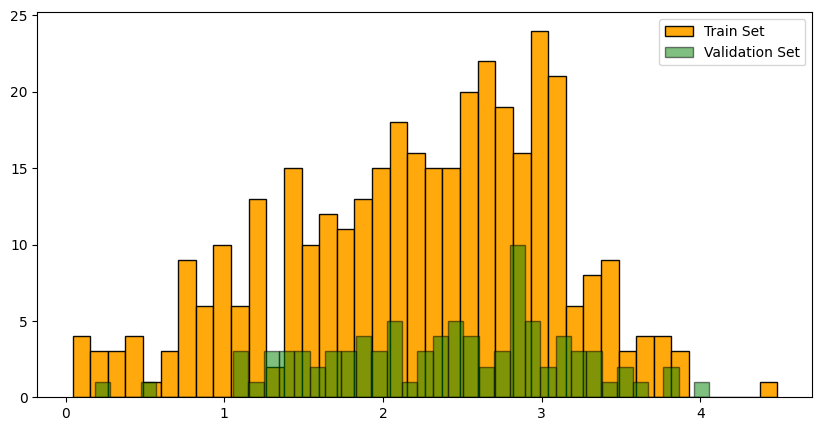

In [17]:
df_sample = df_paths[df_paths['scenario_name'].isin(sampled_scenarios)].reset_index(drop=True)
df_sample = df_sample.sample(frac=1, random_state=42).reset_index(drop=True)

n_train = round(len(df_sample)*80/100)
print(f"Size of training dataset = {n_train}")
print(f"Size of validation dataset = {len(df_sample)-n_train}")

# full dataset
df_train = df_sample[0:n_train]
df_val = df_sample[n_train:]
df_test = df_paths[~df_paths['scenario_name'].isin(sampled_scenarios)].reset_index(drop=True)
df_test = df_test.sample(n=10, random_state=42).reset_index(drop=True)

#plot the histogram of max_off to check the distribution
plt.figure(figsize=(10, 5))
plt.hist(df_train[max_off], bins=nbins, color='orange', alpha=0.95, edgecolor='black', label='Train Set')
plt.hist(df_val[max_off], bins=nbins, color='green', alpha=0.5, edgecolor='black',label='Validation Set')   
plt.legend()
plt.show()

### Download Data from SDL


In order to build our ML emulator we neew to download the selected data locally. 
The data to download are:
   - *grid_file*: topografy of target area
   - *df_sample*: scenarios sampled for training and validation of the model
   - *df_test*: sceanrios selected for testing the model

##### download grid file

In [18]:
sdl_utl.download_sdl_file(download_dir=path_experiment_dataset,file_sdl_path=grid_file,sdl_client=client)

......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd already exists


##### download simulations ouput

In [19]:
### download test data
for i, (scenario, file_ct, file_ts) in enumerate(zip(df_test['scenario_name'], df_test['c_nc'], df_test['grid0_ts'])):
    print(f"{i}: Scenario {scenario}")
    ###
    sdl_utl.download_sdl_file(download_dir=path_experiment_dataset,file_sdl_path=file_ct,sdl_client=client)
    sdl_utl.download_sdl_file(download_dir=path_experiment_dataset,file_sdl_path=file_ts,sdl_client=client)
    if i % 50 == 0:
        ### refresh token
        client.auth.login()

0: Scenario E01548N3896E01854N3659-PS-Str_PYes_Hom-M837_E01708N3793_S000
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Hom-M837_E01708N3793_S000/C_CT.nc already exists
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Hom-M837_E01708N3793_S000/grid0_ts.nc already exists
{'response': 200, 'message': 'Authenticated on SDL successfully.'}
1: Scenario E02020N3739E02658N3366-PS-Mur_PYes_Var-M774_E02267N3478_S000
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Mur_PYes_Var-M774_E02267N3478_S000/C_CT.nc already exists
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Mur_PYes_Var-M774_E02267N3478_S000/grid0_ts.nc already exists
2: Scenario E02020N3739E02658N3366-PS-Str_PYes_Hom-M895_E02217N3548_S005
......File: /data/users/adistefano/ml_emulator/downloa

In [20]:
### download training and validation data
for i, (scenario, file_ct, file_ts) in enumerate(zip(df_sample['scenario_name'], df_sample['c_nc'], df_sample['grid0_ts'])):
    print(f"{i}: Scenario {scenario}")
    ###
    sdl_utl.download_sdl_file(download_dir=path_experiment_dataset,file_sdl_path=file_ct,sdl_client=client)
    sdl_utl.download_sdl_file(download_dir=path_experiment_dataset,file_sdl_path=file_ts,sdl_client=client)
    if i % 50 == 0:
        ### refresh token
        client.auth.login()

0: Scenario E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E02232N3550_S001
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E02232N3550_S001/C_CT.nc already exists
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Hom-M902_E02232N3550_S001/grid0_ts.nc already exists
{'response': 200, 'message': 'Authenticated on SDL successfully.'}
1: Scenario E01548N3896E01854N3659-PS-Str_PYes_Var-M850_E01783N3758_S000
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Var-M850_E01783N3758_S000/C_CT.nc already exists
......File: /data/users/adistefano/ml_emulator/download_data/CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Var-M850_E01783N3758_S000/grid0_ts.nc already exists
2: Scenario E02020N3739E02658N3366-PS-Str_PYes_Var-M895_E02351N3465_S005
......File: /data/users/adistefano/ml_emulator/downloa

### Build ML Inundation Emulator

Lets build an inudation emulator using the above selection of scenarios training set and by selecting some pois off coast of the site.

##### Select POIS offshore

The grid where time series are saved, file named *grid0_ts.nc*, is composed by two separate rectangular sub-grid: one around area of Catania e one around area of Siracusa.

   1. Catania grid: covers the area bounded between longitudes $15.022^\circ\text{ E}$ and $15.125^\circ\text{ E}$ and latitudes $37.310^\circ\text{ N}$ and $37.511^\circ\text{ N}$, consisting of 47 columns $\times$ 112 rows for a total of 5264 points

   2. Siracusa grid: covers the area bounded between longitudes $15.196^\circ\text{ E}$ and $15.344^\circ\text{ E}$ and latitudes $36.999^\circ\text{ N}$ and $37.084^\circ\text{ N}$, consisting of 67 columns $\times$ 48 rows for a total of 3216 points.

Below we select 15 points uniformly distribuited around the given site

In [21]:
n_points = 15

### suggested POIS for Catania
offset = 0
col_id = 45
total_rows = 112
n_cols = 47
rows = np.linspace(0, total_rows - 1, n_points, dtype=int)
POIS = [offset + col_id + int(r) * n_cols for r in rows]

### suggested POIS for Siracusa
#offset = 5264
#col_id = 66
#total_rows = 48
#n_cols = 67
#rows = np.linspace(0, total_rows - 1, n_points, dtype=int)
#POIS = [offset + col_id + int(r) * n_cols for r in rows]

plot selected POIS

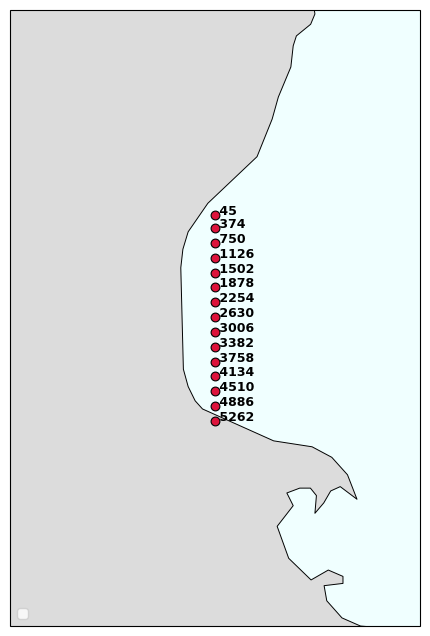

In [22]:
### open a time series file
ds_ts = xr.open_dataset(os.path.join(path_experiment_dataset, file_ts))
lons = ds_ts['longitude'].values
lats = ds_ts['latitude'].values

# select coordinates of selected pois
sub_lons = lons[POIS]
sub_lats = lats[POIS]
sub_ids = list(POIS)

fig, ax = plt.subplots(figsize=(14, 8),subplot_kw={'projection': ccrs.PlateCarree()})

# Add Layer
ax.add_feature(cfeature.LAND, facecolor='gainsboro', edgecolor='none')
ax.add_feature(cfeature.OCEAN, facecolor='azure', edgecolor='none')
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)

# Plot dei punti dell'intervallo
ax.scatter(
    sub_lons,
    sub_lats,
    color='crimson',
    s=40,
    edgecolor='black',
    linewidth=0.8,
    transform=ccrs.PlateCarree(),
    zorder=5
)

# add a label with ID to each POI
for pid, x, y in zip(sub_ids, sub_lons, sub_lats):
    ax.text(x, y, f' {pid}', fontsize=9, fontweight='bold', transform=ccrs.PlateCarree(), zorder=6)

# Extent around selected interval
pad = 0.2
ax.set_extent(
    [sub_lons.min() - pad, sub_lons.max() + pad, sub_lats.min() - pad, sub_lats.max() + pad],
    crs=ccrs.PlateCarree()
)

ax.legend(loc='lower left')
plt.show()

##### Train ML emulator

Runs for about 30 minutes on CPU for 200 epochs for training set of 429 scenarios and 106 validation scenarios

In [23]:
GENERATED_DIR = path_ml_results
NAME="emulator"

# Create rundir
#timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
timestamp = datetime.now().strftime('%Y%m%d')
ID = f"{NAME}_{timestamp}"
RUNDIR = os.path.join(GENERATED_DIR, ID)
print(f"Directory where to save model results: {RUNDIR}")
os.makedirs(RUNDIR, exist_ok=True)

# file with grid
TOPO_FILE = grid_file
# file with training files (relative) paths
TRAIN_SCENARIOS = os.path.join(RUNDIR, "train_scenarios.csv")
# file with validation files (relative) paths
VALIDATION_SCENARIOS = os.path.join(RUNDIR, "validation.csv")
# file with test files (relative) paths
TEST_SCENARIOS = os.path.join(RUNDIR, "test.csv")
OUT_DIR = os.path.join(RUNDIR,"predictions")
# file to experiment data
TRAIN_DIR = path_experiment_dataset
VALIDATION_DIR = TRAIN_DIR
TEST_DIR = TRAIN_DIR

# Optionally can be set to a specific file from previous run
TOPO_MASK = os.path.join(RUNDIR, "topomask.npy")
GRID_INFO_FILE = os.path.join(RUNDIR, "grid_info.json")

Directory where to save model results: /data/users/adistefano/ml_emulator/generated/emulator_20261105


In [24]:
# save scenarios configfiles to rundir: train_scenarios, validation_scenarios, topofile
df_train[['scenario_name','c_nc','grid0_ts']].to_csv(TRAIN_SCENARIOS, index=False, header=False)
df_val[['scenario_name','c_nc','grid0_ts']].to_csv(VALIDATION_SCENARIOS, index=False, header=False)
df_test[['scenario_name','c_nc','grid0_ts']].to_csv(TEST_SCENARIOS, index=False, header=False)
# Copy config files to rundir
shutil.copy(os.path.join(TRAIN_DIR,TOPO_FILE), os.path.join(RUNDIR, "topography.grd"))


# Creates topomask on initialization if it does not exists
reader = DataReader(
    rundir=RUNDIR,
    scenarios_file=TRAIN_SCENARIOS,
    datadir=TRAIN_DIR,
)

if TOPO_MASK and os.path.isfile(TOPO_MASK):
    if not TOPO_MASK.endswith(".npy"):
        raise ValueError(f"Invalid file extension: {TOPO_MASK}. Expected a .npy file.")
    else:
        reader.logger.info(f"TOPO_MASK found at {TOPO_MASK}")
else: 
    reader.logger.warning(f"TOPO_MASK ({TOPO_MASK}) not found. Creating a new mask.")
    reader.create_mask()

# Understand what is doing: it seams that the information extracted are the one contained in C_CT.grd (and lon==grid_lon & lat==grid_lat)
if GRID_INFO_FILE and os.path.isfile(GRID_INFO_FILE):
    reader.logger.info(f"GRID_INFO found at {GRID_INFO_FILE}")
else: 
    reader.logger.warning(f"GRID_INFO_FILE ({GRID_INFO_FILE}) not found. Creating a new mask.")
    reader.store_grid_info()

2026-11-05 14:48:15,064 - src_ml_emulator.data_reader - INFO - TOPO_MASK found at /data/users/adistefano/ml_emulator/generated/emulator_20261105/topomask.npy
2026-11-05 14:48:15,065 - src_ml_emulator.data_reader - INFO - GRID_INFO found at /data/users/adistefano/ml_emulator/generated/emulator_20261105/grid_info.json


In [25]:
# All config files should be available in the rundir.
emulator = Emulator(GENERATED_DIR, RUNDIR, POIS)

2026-11-05 14:48:19.289734: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
2026-11-05 14:48:19,447 - src_ml_emulator.emulator - INFO - Encoder:


2026-11-05 14:48:19,453 - src_ml_emulator.emulator - INFO - Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape (Reshape)               │ (None, 15, 481, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 13, 479, 8)     │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 13, 479, 8)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 11, 239, 8)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 9, 235, 16)     │         1,92

2026-11-05 14:48:19,457 - src_ml_emulator.emulator - INFO - Model: "sequential_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 291661)         │    18,957,

In [26]:
emulator.train_model(train_dir = TRAIN_DIR, 
                        train_scenarios = TRAIN_SCENARIOS,
                        validation_dir = VALIDATION_DIR,
                        validation_scenarios = VALIDATION_SCENARIOS,
                        batch_size=30,
                        epochs=200,
                        l2_callback_frequency=20,
                        save_model_frequency=100)

#print()

2026-11-05 14:48:24,037 - src_ml_emulator.emulator - INFO - Number of training scenarios: 364
2026-11-05 14:48:24,153 - src_ml_emulator.emulator - INFO - Training started.


Epoch 1/200


E0000 00:00:1793890105.132603 1524274 meta_optimizer.cc:967] remapper failed: INVALID_ARGUMENT: Mutation::Apply error: fanout 'StatefulPartitionedCall/gradient_tape/sequential_2_1/sequential_1/leaky_re_lu_3_1/LeakyRelu/LeakyReluGrad' exist for missing node 'StatefulPartitionedCall/sequential_2_1/sequential_1/conv2d_3_1/BiasAdd'.
2026-11-05 14:48:35.217979: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:453] ShuffleDatasetV3:7: Filling up shuffle buffer (this may take a while): 101 of 364
2026-11-05 14:48:45.256166: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:453] ShuffleDatasetV3:7: Filling up shuffle buffer (this may take a while): 203 of 364
2026-11-05 14:48:55.258335: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:453] ShuffleDatasetV3:7: Filling up shuffle buffer (this may take a while): 308 of 364


      1/Unknown 37s 37s/step - loss: 1.5186 - mse: 0.3985

2026-11-05 14:49:00.781485: I tensorflow/core/kernels/data/shuffle_dataset_op.cc:483] Shuffle buffer filled.


     13/Unknown 38s 77ms/step - loss: 1.5520 - mse: 0.4047

... (397 outputs left out)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 132ms/step - loss: 0.0200 - mse: 0.0143 - val_loss: 0.0202 - val_mse: 0.0137
Epoch 200/200
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - loss: 0.0181 - mse: 0.0131

2026-11-05 14:56:36,383 - src_ml_emulator.emulator - INFO - Model saved at: /data/users/adistefano/ml_emulator/generated/emulator_20261105/model_checkpoints/model_epoch_200.keras
2026-11-05 14:56:36,385 - src_ml_emulator.emulator - INFO - Epoch 200: loss=0.0194, mse=0.0136, val_loss=0.0366, val_mse=0.0357


13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 758ms/step - loss: 0.0194 - mse: 0.0136 - val_loss: 0.0366 - val_mse: 0.0357


2026-11-05 14:56:36,391 - src_ml_emulator.emulator - INFO - Training completed.


Save: trained model, training plots and predictions on test dataset

In [27]:
emulator.save_model()

In [28]:
# Create and save plots.
plotter = Plotter(emulator.rundir)
plotter.plot_l2_metrics_overlay()
plotter.plot_training_history()

2026-11-05 14:59:37,052 - src_ml_emulator.plotter - INFO - Saved scatterplot for Epoch 20 at /data/users/adistefano/ml_emulator/generated/emulator_20261105/plots/scatter_epoch_20.png
2026-11-05 14:59:37,230 - src_ml_emulator.plotter - INFO - Saved scatterplot for Epoch 40 at /data/users/adistefano/ml_emulator/generated/emulator_20261105/plots/scatter_epoch_40.png
2026-11-05 14:59:37,791 - src_ml_emulator.plotter - INFO - Saved scatterplot for Epoch 60 at /data/users/adistefano/ml_emulator/generated/emulator_20261105/plots/scatter_epoch_60.png
2026-11-05 14:59:37,969 - src_ml_emulator.plotter - INFO - Saved scatterplot for Epoch 80 at /data/users/adistefano/ml_emulator/generated/emulator_20261105/plots/scatter_epoch_80.png
2026-11-05 14:59:38,150 - src_ml_emulator.plotter - INFO - Saved scatterplot for Epoch 100 at /data/users/adistefano/ml_emulator/generated/emulator_20261105/plots/scatter_epoch_100.png
2026-11-05 14:59:38,323 - src_ml_emulator.plotter - INFO - Saved scatterplot for Ep

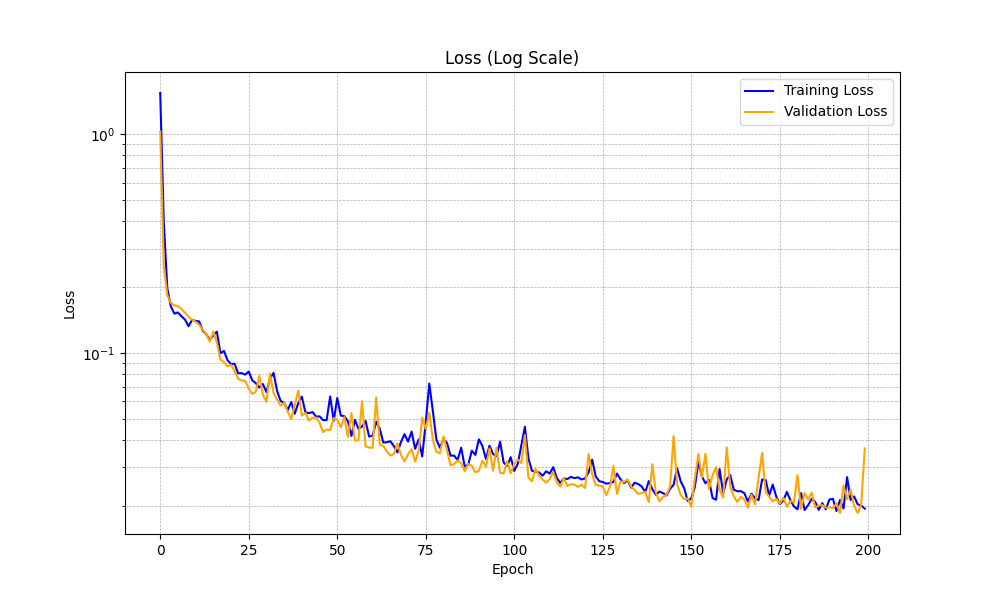

In [29]:
display(Image(f'{RUNDIR}/train_summary_loss.png'))

In [30]:
### make predictions over selected test scenarios
emulator.predict(                
    scenarios_file=TEST_SCENARIOS,
    input_dir=TEST_DIR,
    output_dir=OUT_DIR
)

2026-11-05 14:59:45,178 - src_ml_emulator.emulator - INFO - Number of scenarios for prediction: 10
2026-11-05 14:59:46,910 - src_ml_emulator.emulator - INFO - NetCDF file created: /data/users/adistefano/ml_emulator/generated/emulator_20261105/predictions/E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E02349N3441_S003_predictions.nc
2026-11-05 14:59:46,920 - src_ml_emulator.emulator - INFO - NetCDF file created: /data/users/adistefano/ml_emulator/generated/emulator_20261105/predictions/E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02401N3479_S005_predictions.nc
2026-11-05 14:59:46,930 - src_ml_emulator.emulator - INFO - NetCDF file created: /data/users/adistefano/ml_emulator/generated/emulator_20261105/predictions/E02020N3739E02658N3366-PS-Mur_PYes_Var-M861_E02166N3518_S004_predictions.nc
2026-11-05 14:59:46,939 - src_ml_emulator.emulator - INFO - NetCDF file created: /data/users/adistefano/ml_emulator/generated/emulator_20261105/predictions/E01548N3896E01854N3659-PS-Str_PYes_Var-M809_E0169

### Model evaluation

Training loss function

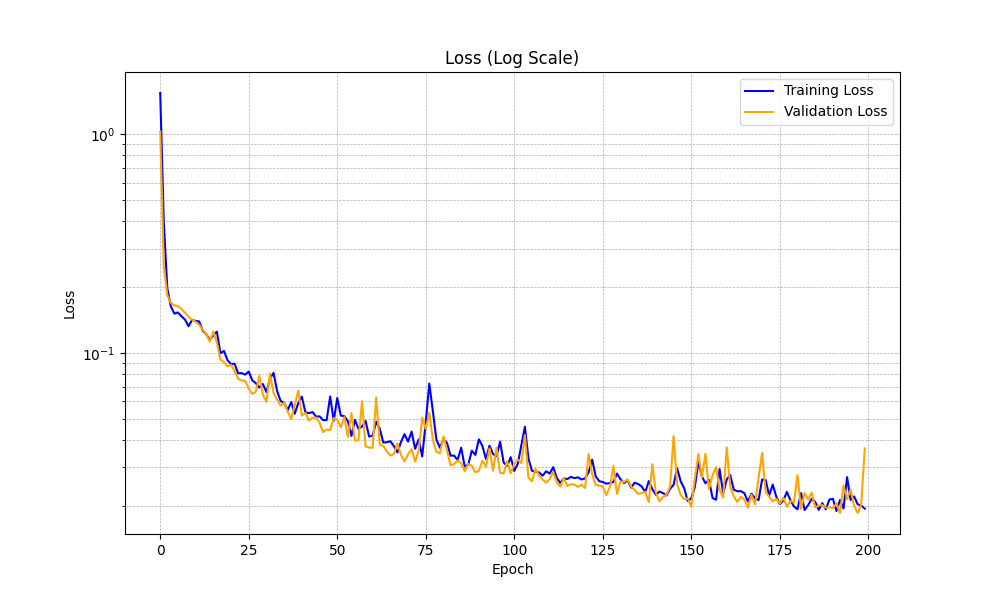

In [31]:
display(Image(f'{RUNDIR}/train_summary_loss.png'))

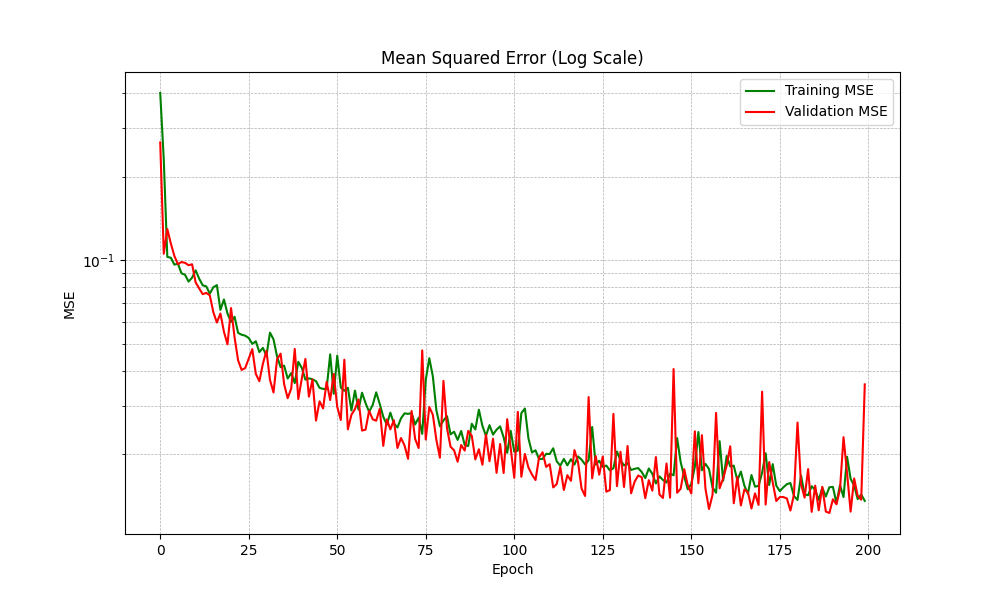

In [32]:
display(Image(f'{RUNDIR}/train_summary_mse.png'))

Lets evaluate the emulator prediction by comparing against the simulated inundation depth, we will use the data read to calculate the depth from height and elevation 

In [33]:
datareader=DataReader(
                    rundir=RUNDIR,
                    scenarios_file=TEST_SCENARIOS,
                    datadir=TEST_DIR
                    )
topo_mask = datareader.topomask
#
with open(GRID_INFO_FILE) as f:
    grid_info_tmp = json.load(f)
lat = grid_info_tmp['variables']['lat']['data']
lon = grid_info_tmp['variables']['lon']['data']
#
lon2d, lat2d = np.meshgrid(lon, lat)
lon_mask = lon2d[topo_mask]
lat_mask = lat2d[topo_mask]


Processing scenario: E01548N3896E01854N3659-PS-Str_PYes_Hom-M837_E01708N3793_S000
Analyze file CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Hom-M837_E01708N3793_S000/C_CT.nc


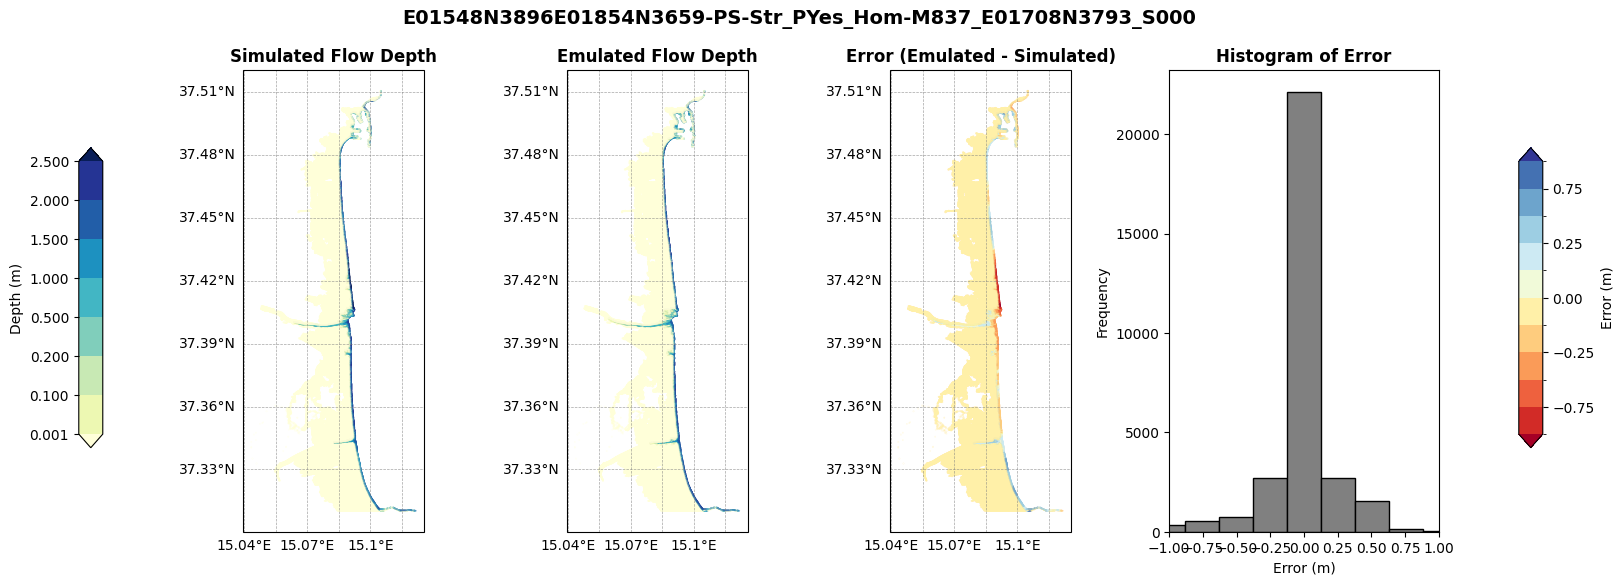

Processing scenario: E02020N3739E02658N3366-PS-Mur_PYes_Var-M774_E02267N3478_S000
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Mur_PYes_Var-M774_E02267N3478_S000/C_CT.nc


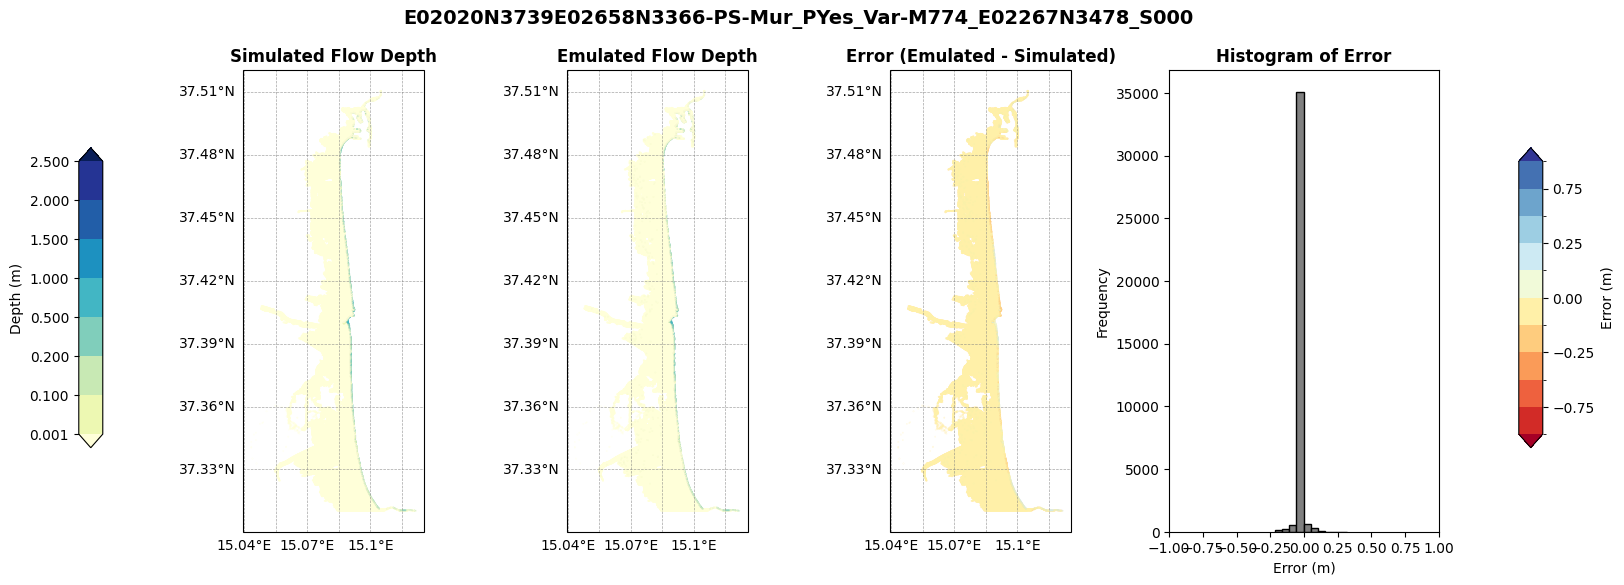

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Hom-M895_E02217N3548_S005
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Hom-M895_E02217N3548_S005/C_CT.nc


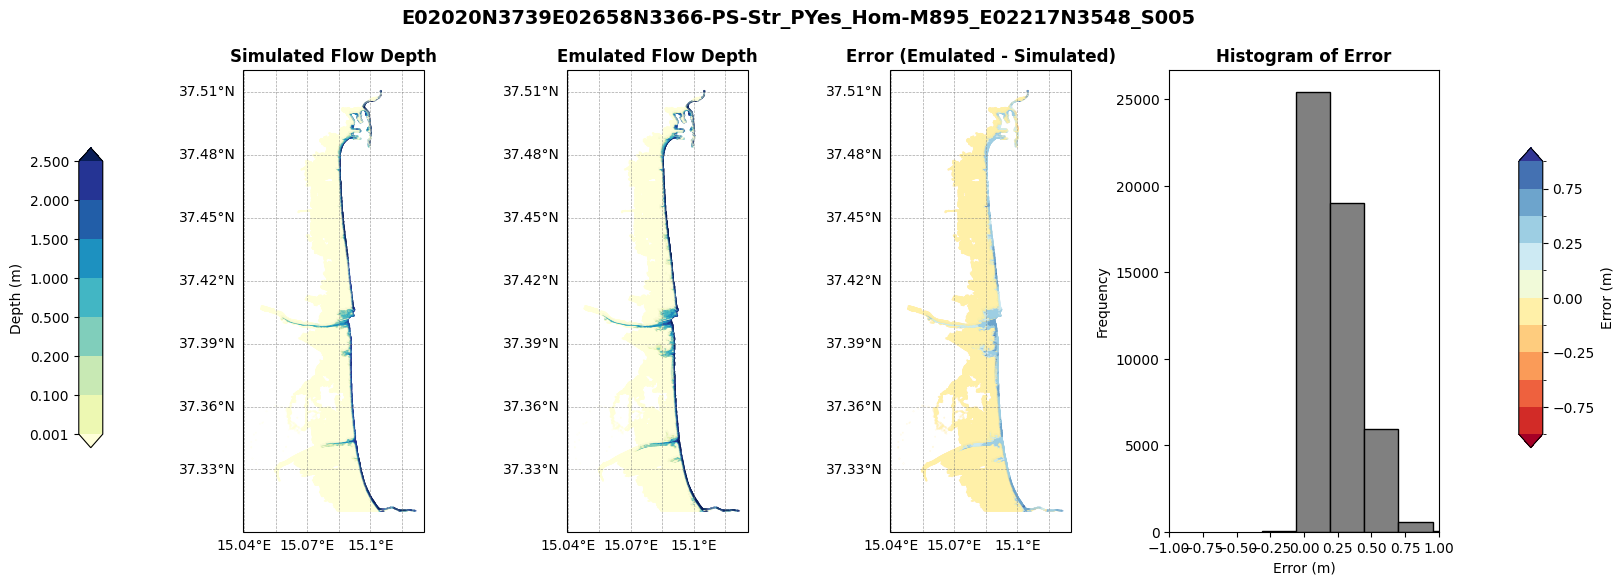

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02218N3525_S003
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02218N3525_S003/C_CT.nc


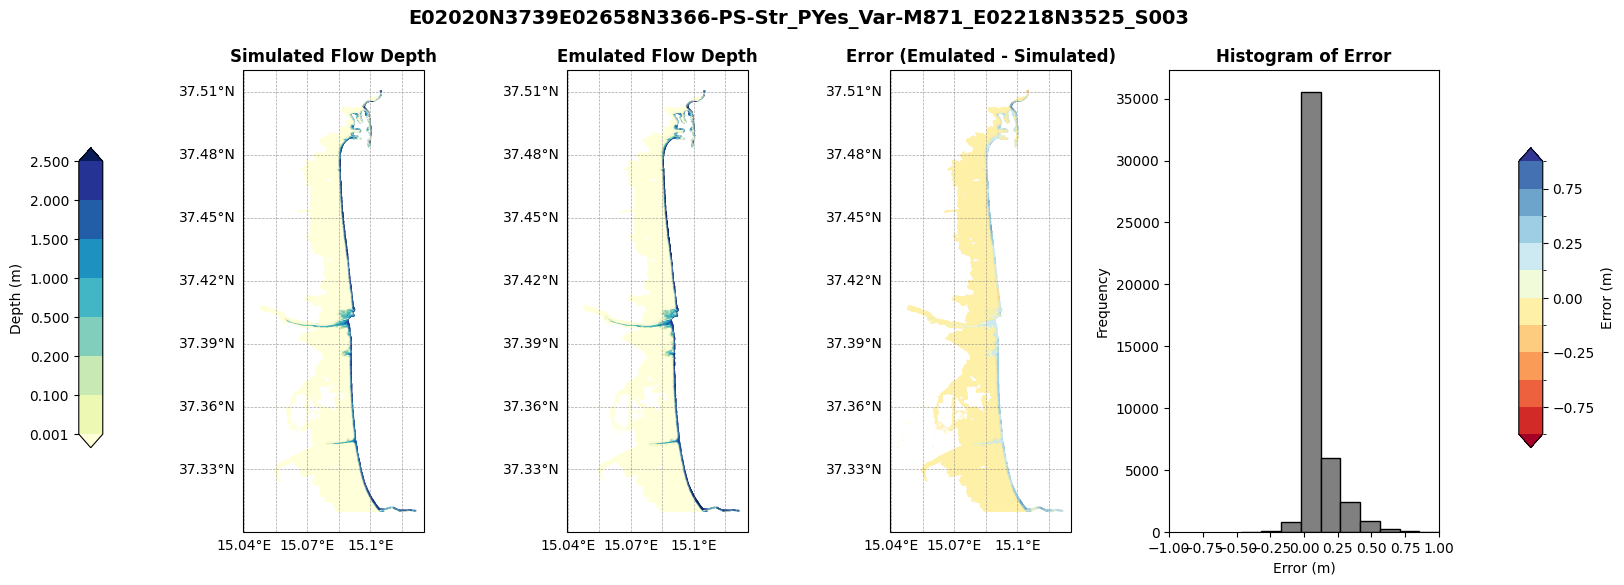

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Var-M902_E02318N3471_S001
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Var-M902_E02318N3471_S001/C_CT.nc


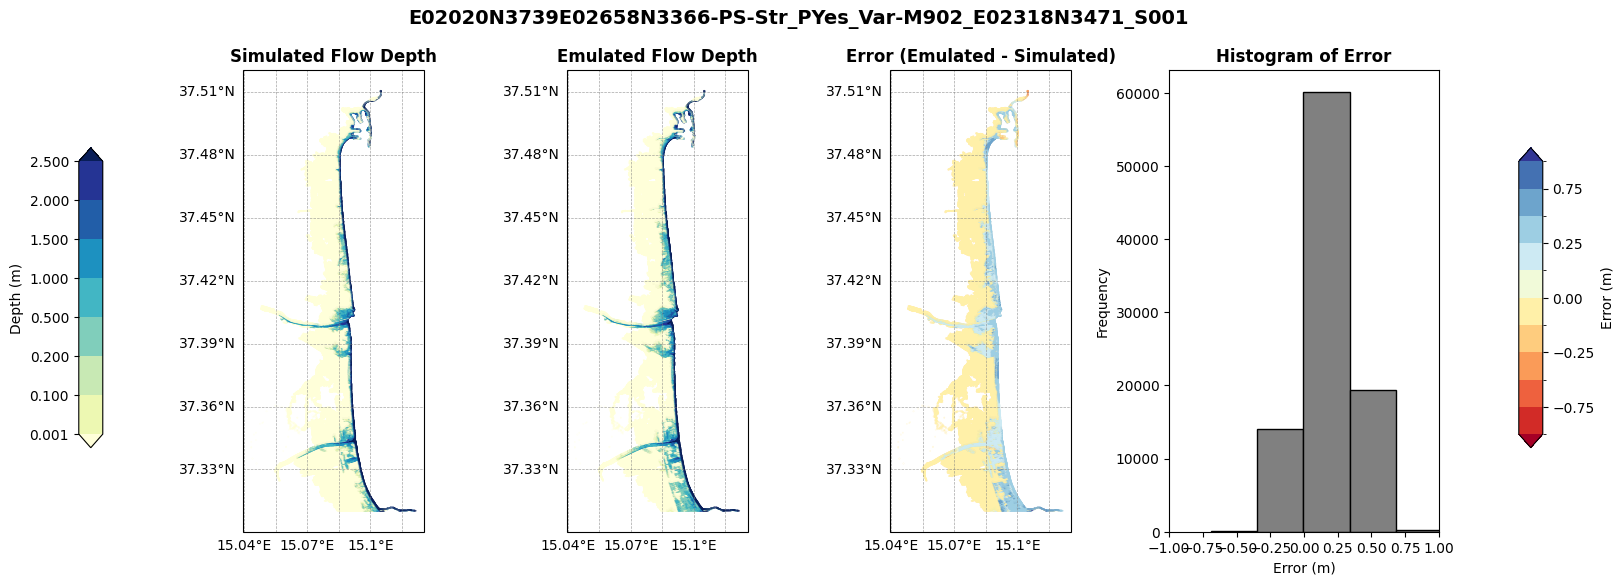

Processing scenario: E01548N3896E01854N3659-PS-Mur_PYes_Var-M792_E01612N3787_S000
Analyze file CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Mur_PYes_Var-M792_E01612N3787_S000/C_CT.nc


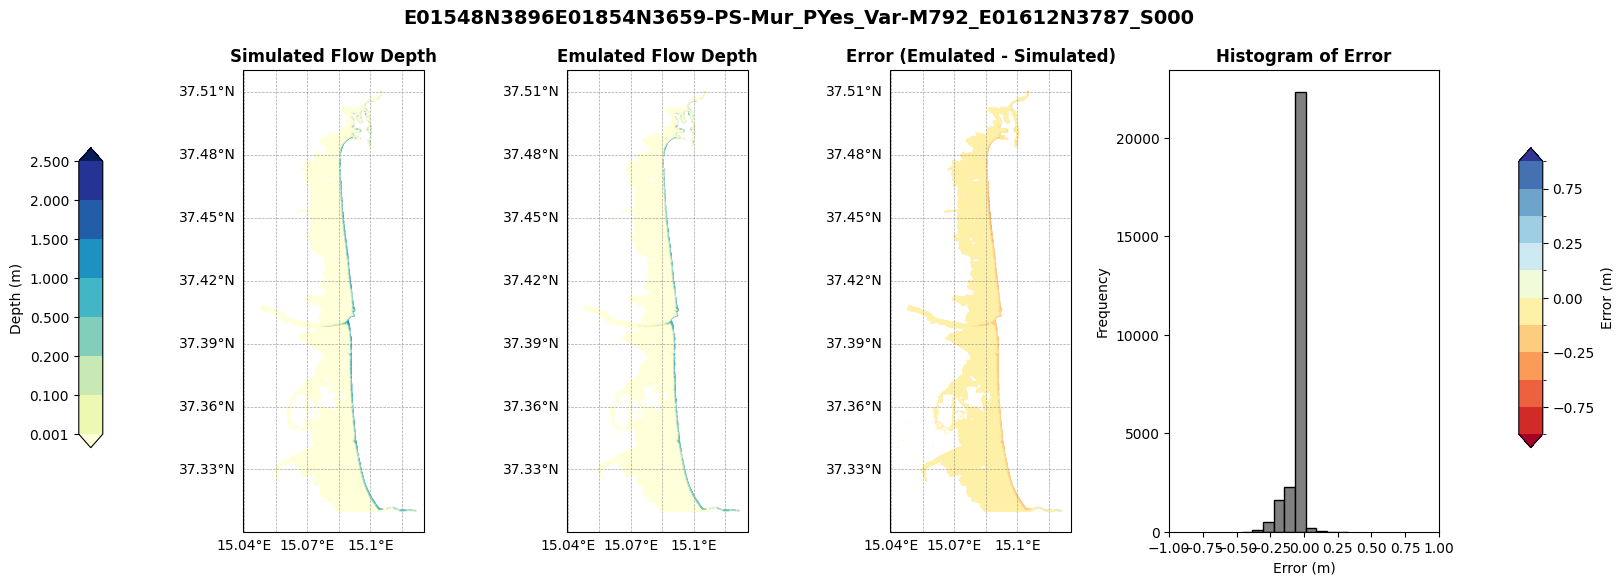

Processing scenario: E01548N3896E01854N3659-PS-Str_PYes_Var-M809_E01699N3763_S000
Analyze file CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Str_PYes_Var-M809_E01699N3763_S000/C_CT.nc


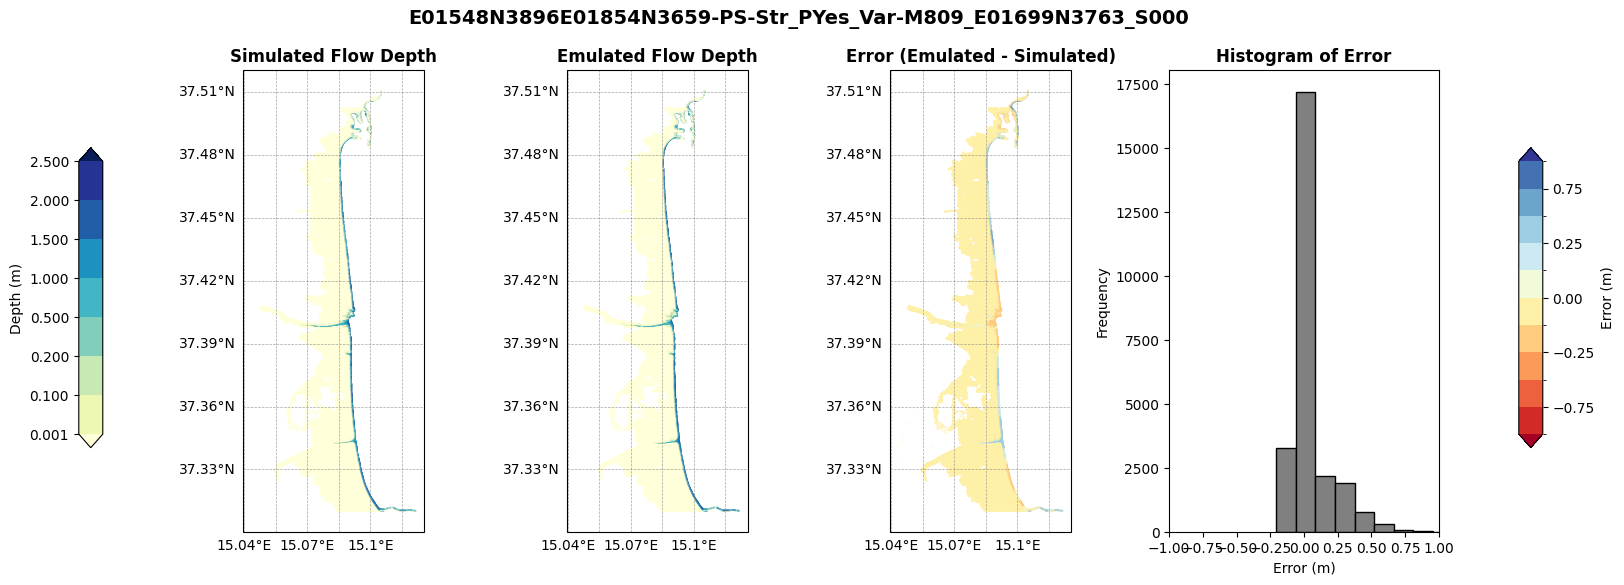

Processing scenario: E02020N3739E02658N3366-PS-Mur_PYes_Var-M861_E02166N3518_S004
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Mur_PYes_Var-M861_E02166N3518_S004/C_CT.nc


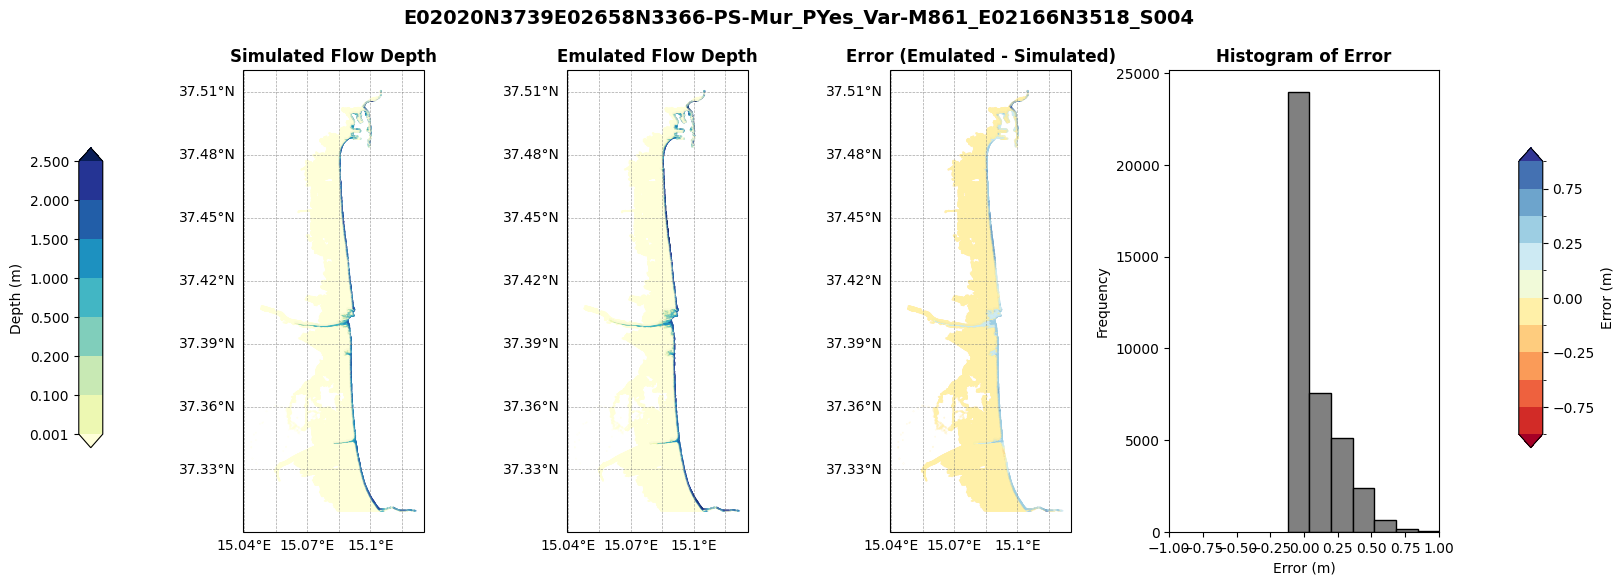

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02401N3479_S005
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Var-M871_E02401N3479_S005/C_CT.nc


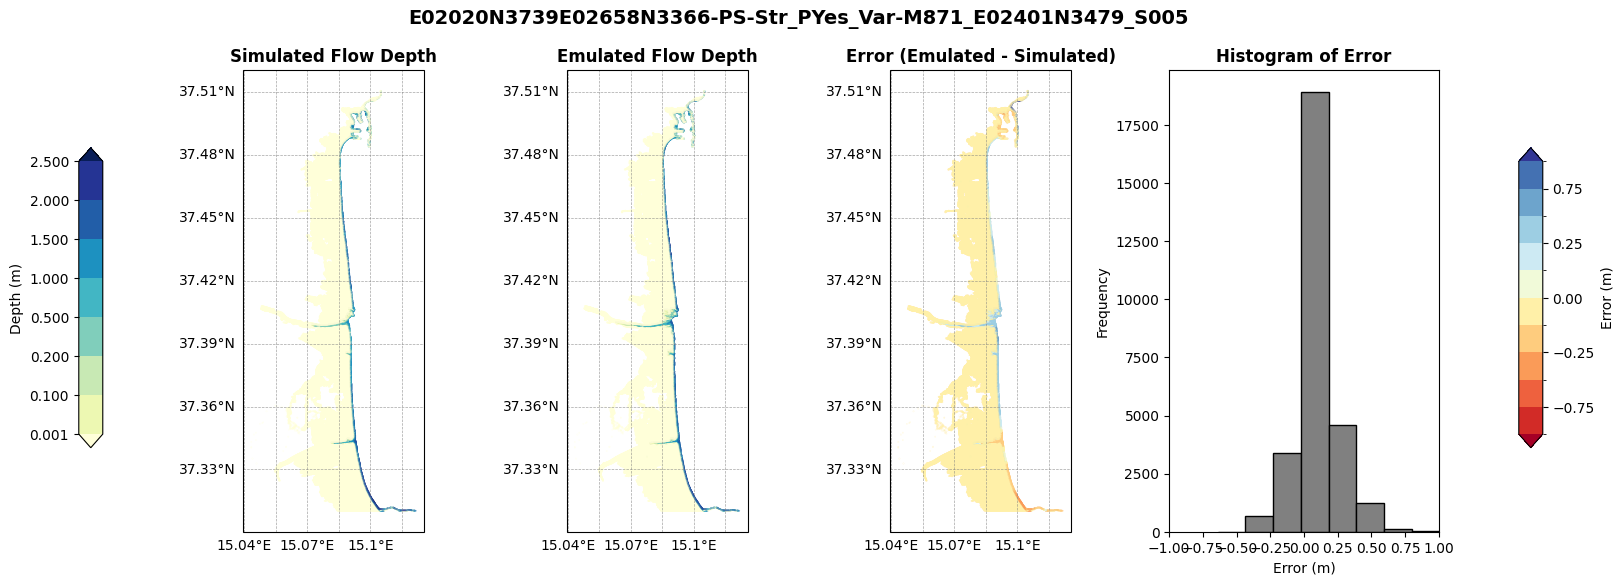

Processing scenario: E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E02349N3441_S003
Analyze file CT-SR_M100/PS_006/E02020N3739E02658N3366-PS-Str_PYes_Hom-M861_E02349N3441_S003/C_CT.nc


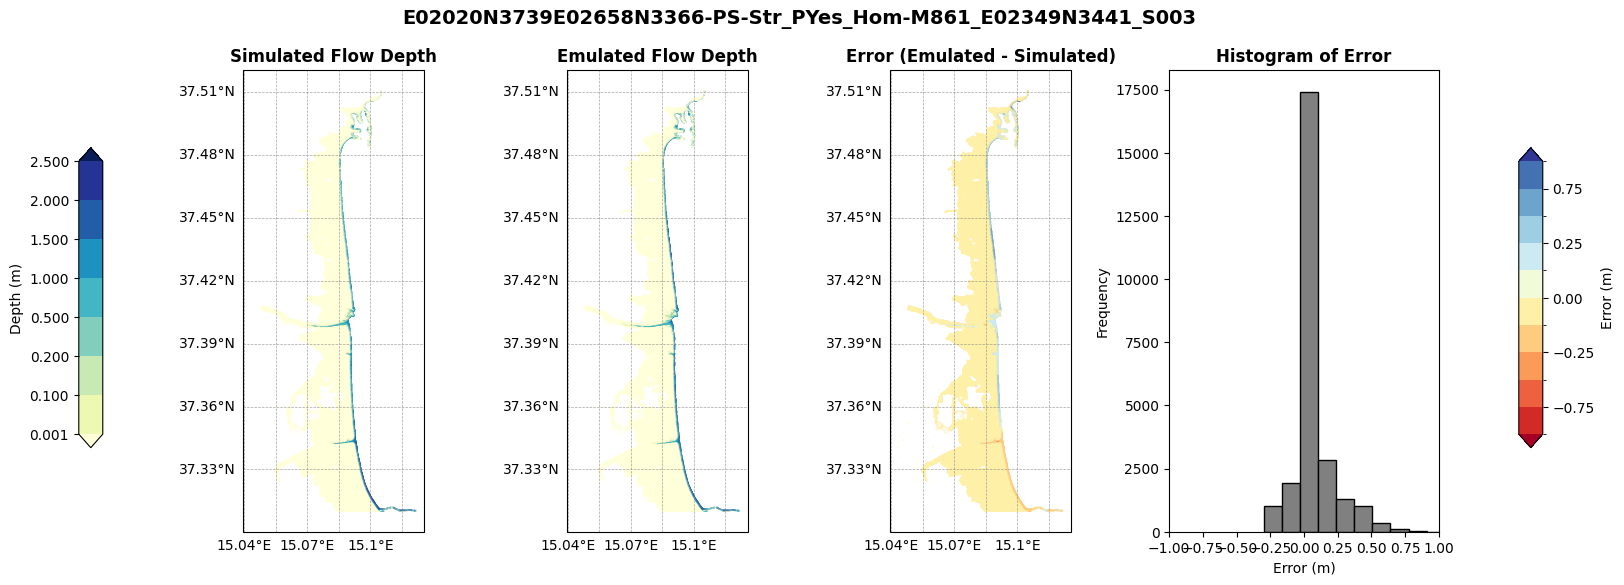

In [34]:
df_test = pd.read_csv(TEST_SCENARIOS,header=None,names=['scenario_name','c_ct','grid0_ts'])
for scenario_name, file_ct in zip(df_test.scenario_name,df_test.c_ct):  # Loop through all scenarios

    # Read the data for the scenario
    print(f"Processing scenario: {scenario_name}")
    print(f"Analyze file {file_ct}")
    simulated_depth,_ = datareader.get_flow_depth(path_file_ct=file_ct,full_path=False)
    emulated_ds = xr.open_dataset(os.path.join(OUT_DIR, f"{scenario_name}_predictions.nc"))
        
    z_sim = simulated_depth
    z_emul = emulated_ds.predicted.values[topo_mask]  # Emulated depth from the prediction
    error = z_emul - z_sim  # Error map

    # Setup figure and subplots
    fig, axs = plt.subplots(1, 4, figsize=(16, 6), subplot_kw={'projection': ccrs.PlateCarree()})
    depth_cmap = colormaps['YlGnBu']
    depth_bounds = [0.001, 0.1, 0.2, 0.5, 1, 1.5, 2, 2.5]
    depth_norm = colors.BoundaryNorm(depth_bounds, depth_cmap.N, extend='both')

    # --- Plot 1: Simulated ---
    sc0 = axs[0].scatter(lon_mask, lat_mask, c=z_sim, cmap=depth_cmap, norm=depth_norm, s=0.01, transform=ccrs.PlateCarree())
    axs[0].set_title("Simulated Flow Depth", fontsize=12, fontweight="bold")
    gl0 = axs[0].gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
    gl0.top_labels = gl0.right_labels = False
    gl0.xformatter = cticker.LongitudeFormatter()
    gl0.yformatter = cticker.LatitudeFormatter()

    # --- Plot 2: Emulated ---
    sc1 = axs[1].scatter(lon_mask, lat_mask, c=z_emul, cmap=depth_cmap, norm=depth_norm, s=0.01, transform=ccrs.PlateCarree())
    axs[1].set_title("Emulated Flow Depth", fontsize=12, fontweight="bold")
    gl1 = axs[1].gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
    gl1.top_labels = gl1.right_labels = False
    gl1.xformatter = cticker.LongitudeFormatter()
    gl1.yformatter = cticker.LatitudeFormatter()

    # --- Plot 3: Error Map ---
    error_cmap = colormaps['RdYlBu']
    error_bounds = [-1, -0.75, -0.5, -0.25, -0.05, 0, 0.05, 0.25, 0.5, 0.75, 1]
    error_norm = colors.BoundaryNorm(error_bounds, error_cmap.N, extend='both')

    sc2 = axs[2].scatter(lon_mask, lat_mask, c=error, cmap=error_cmap, norm=error_norm, s=0.01, transform=ccrs.PlateCarree())
    axs[2].set_title("Error (Emulated - Simulated)", fontsize=12, fontweight="bold")
    gl2 = axs[2].gridlines(draw_labels=True, linestyle="--", linewidth=0.5, color="gray", alpha=0.7)
    gl2.top_labels = gl2.right_labels = False
    gl2.xformatter = cticker.LongitudeFormatter()
    gl2.yformatter = cticker.LatitudeFormatter()

    # --- Plot 4: Error Histogram ---
    # Remove projection for this subplot
    axs[3].remove()
    ax4 = fig.add_subplot(1, 4, 4)  # regular axes for histogram
    error_filter = error[np.abs(error) >= 0.01]
    ax4.hist(error_filter, bins=10, color='gray', edgecolor='black')
    ax4.set_xlim(-1, 1)
    ax4.set_xticks(np.arange(-1, 1.1, 0.25))
    ax4.set_xlabel("Error (m)")
    ax4.set_ylabel("Frequency")
    ax4.set_title("Histogram of Error", fontsize=12, fontweight="bold")

    # --- Colorbars ---
    # Depth colorbar on the left of first subplot
    cbar_ax1 = fig.add_axes([0.05, 0.25, 0.015, 0.5])
    cbar1 = fig.colorbar(sc1, cax=cbar_ax1)
    cbar1.set_label('Depth (m)')
    cbar1.ax.yaxis.set_label_position('left')
    cbar1.ax.yaxis.set_ticks_position('left')

    # Error colorbar on the right of error map (3rd plot)
    cbar_ax2 = fig.add_axes([0.95, 0.25, 0.015, 0.5])
    cbar2 = fig.colorbar(sc2, cax=cbar_ax2)
    cbar2.set_label('Error (m)')

    plt.suptitle(f"{scenario_name}", fontsize=14, fontweight="bold")
    plt.show()
    #break
